# Kalman Filter Trading Strategy

**Author**: Matthew Bradshaw

**Date**: September 2026

## Overview

This project implements a pairs trading strategy on the same two bond ETFs used in my previous
project (**IUSB**, the iShares Core Total USD Bond Market ETF, and **JCPB**, the JPMorgan Core Plus
Bond ETF), but replaces the static OLS hedge ratio with a **dynamic hedge ratio estimated by a
Kalman filter**.

## Motivation

In the `PAIRS` project the hedge ratio was estimated once, by OLS over the full 1000-day sample
(0.8852), and then held fixed. The strategy performed reasonably in 2022 - 2023 but deteriorated
from 2024 onwards (the win rate fell from 50% to about 31% while the number of trades rose
sharply). My interpretation was that the bond market had moved into a lower-volatility regime, so a
single fixed hedge ratio no longer described the relationship between the two ETFs and the signal
began trading on minor noise.

A Kalman filter treats the hedge ratio as a hidden quantity that drifts slowly through time and
re-estimates it every day as a new pair of prices arrives. The question this project asks is:
**does letting the hedge ratio adapt improve the strategy, particularly in the later, quieter
period?**

## Methodology

**1. Data Acquisition** Load 1000 days of historical data from Yahoo Finance for the two ETFs and
combine the close prices into a single data frame.

**2. Dynamic Hedge Ratio** Initialise the hedge ratio with a static OLS fit, then update it one
day at a time with a Kalman filter. This produces a time-varying hedge ratio (beta) rather than a
single constant. The filter is explained in more detail in the next section.

**3. Signal Definition** Build the spread, `IUSB - beta_t * JCPB`, using that day's filtered beta,
and standardise it into a 60-day rolling z-score. The z-score tells us how unusual the current
spread is relative to its recent behaviour.

**4. Trading Rules** Short the spread when the z-score rises above +2, go long the spread when it
falls below -2, and close the position once the z-score is back within +/- 0.5. In between, the
existing position is held.

**5. Strategy Performance** Backtest the rules over the 1000 days, net of transaction costs
(5 bps on the traded notional of both legs), and assess performance with the Sharpe Ratio, Maximum
Drawdown and Win Rate. Results are also split into 2022 - 2023 and 2024 - Present so they can be
compared directly with the static-hedge results from `PAIRS`.

In [70]:
# Libraries
import yfinance as yf  # downloads historical prices from Yahoo Finance
import matplotlib.pyplot as plt  # plotting
import numpy as np  # numerical arrays and maths
import pandas as pd  # data frames and time series
import statsmodels.api as sm   # OLS regression (used to initialise the Kalman filter)
# Larger fonts and figure size so the plots are readable
plt.rcParams.update({'font.size': 22})
plt.rcParams["figure.figsize"] = (12,8)

## The Kalman Filter in Brief

The Kalman filter estimates a quantity we cannot observe directly (here, the hedge ratio) from a
stream of noisy observations (here, daily prices). It rests on two assumptions:

**State equation** The hedge ratio follows a random walk: $\beta_t = \beta_{t-1} + w_t$ with
$w_t \sim N(0, Q)$. It can drift from day to day, but only by a small random amount.

**Observation equation** The IUSB price is the hedge ratio times the JCPB price plus noise:
$\text{IUSB}_t = \beta_t \, \text{JCPB}_t + v_t$ with $v_t \sim N(0, R)$.

Each day the filter then performs two steps:

**1. Predict** Our best guess for today's beta is yesterday's beta, but our uncertainty about it
grows: the variance $P$ of the estimate increases by $Q$.

**2. Update** Compare the IUSB price we predicted with the one we actually saw. The difference is
called the **innovation**. Today's beta is the prediction plus a fraction of the innovation, where
that fraction is the **Kalman gain** $K$. The gain is larger when we are uncertain about beta (large
$P$) or when prices are not very noisy (small $R$), and smaller in the opposite case. After the
update, $P$ shrinks because we have just learned something.

| Symbol | Variable in code | Meaning |
|---|---|---|
| $\beta_t$ | `beta` / `betas` | Filtered hedge ratio after seeing day $t$ |
| $P$ | `P` | Variance (uncertainty) of the beta estimate; starts at `P_0 = 1` |
| $Q$ | `Q` | Process noise: how much beta is allowed to drift each day |
| $R$ | `R` | Observation noise: variance of the OLS residuals |
| $H_t$ | `H` | The JCPB price, which multiplies beta in the observation equation |
| $z_t$ | `z` | The observed IUSB price (not to be confused with the trading z-score) |
| $K_t$ | `K` | Kalman gain |

**Tuning.** The ratio $Q / R$ controls how adaptive the filter is. Here $Q = 10^{-5} R$, which
makes beta move slowly and smoothly; a larger ratio would make it chase each day's noise, and a
smaller one would make it close to static. This value was set by hand and has not been optimised.

**Two differences from the OLS regression in `PAIRS`.** First, this state-space model has no
intercept, so the filtered beta tracks something close to the price ratio of the two ETFs (about
1) and is not directly comparable to the 0.8852 from the OLS fit with a constant. Second, `P_0 = 1`
is very large relative to the observation noise, so the filter places little weight on the OLS
starting value and moves to the data almost immediately.

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


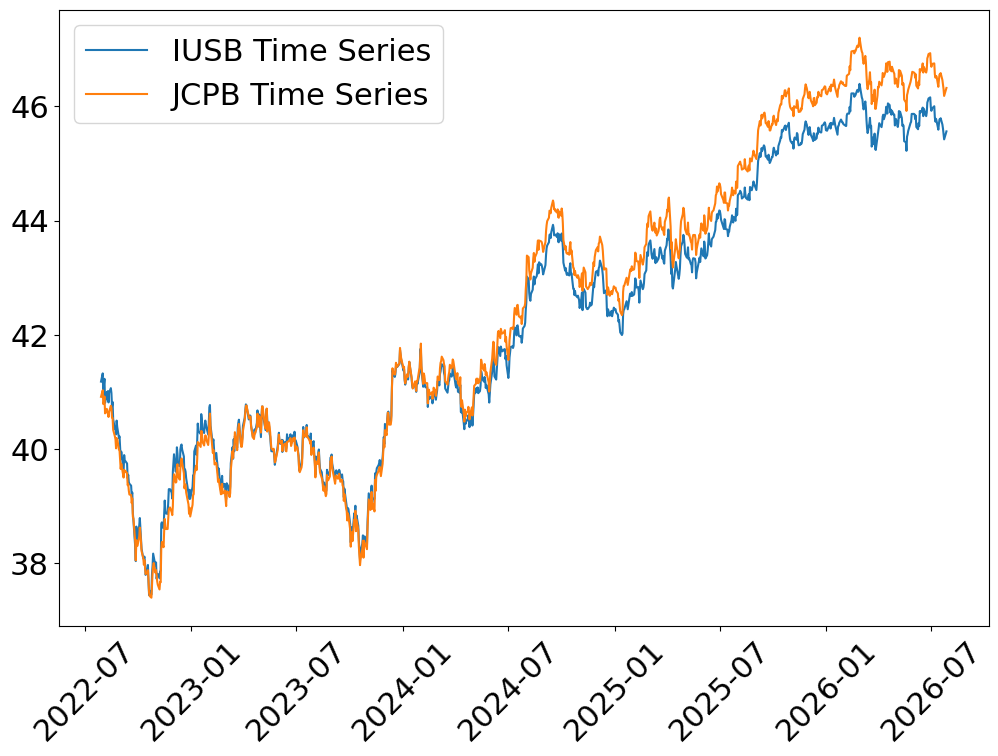

/var/folders/nw/f3v0w82s1gxgxc7j0jts04_w0000gn/T/ipykernel_4220/1544706129.py:66: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta_0 = model.params[1]


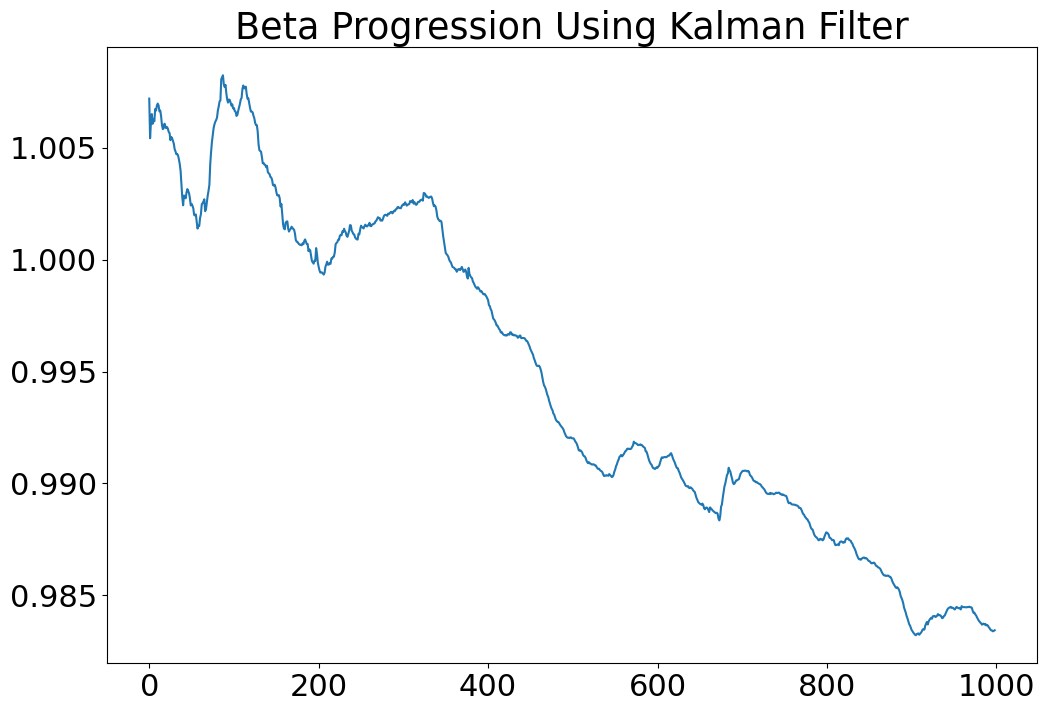

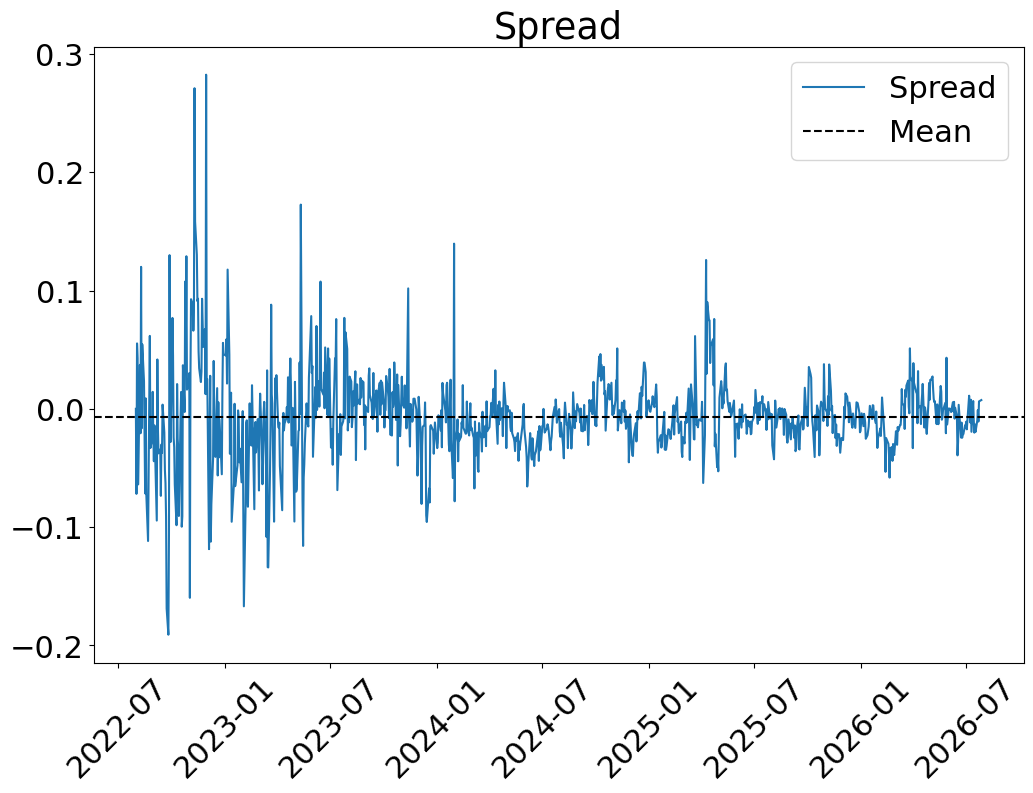

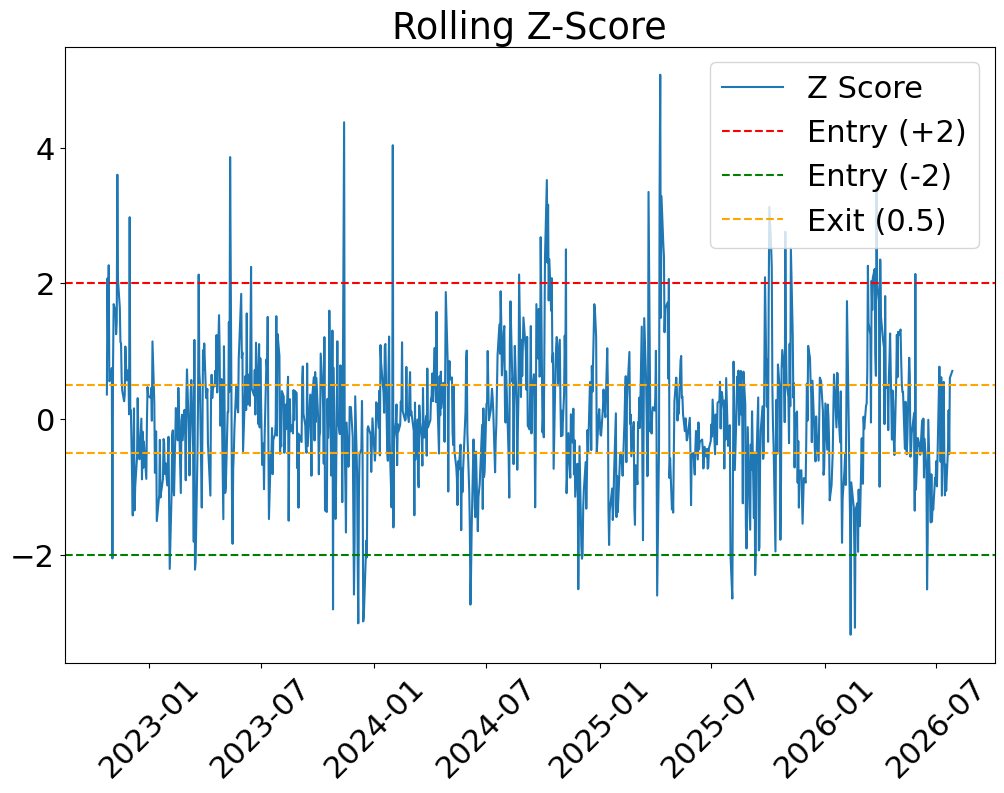

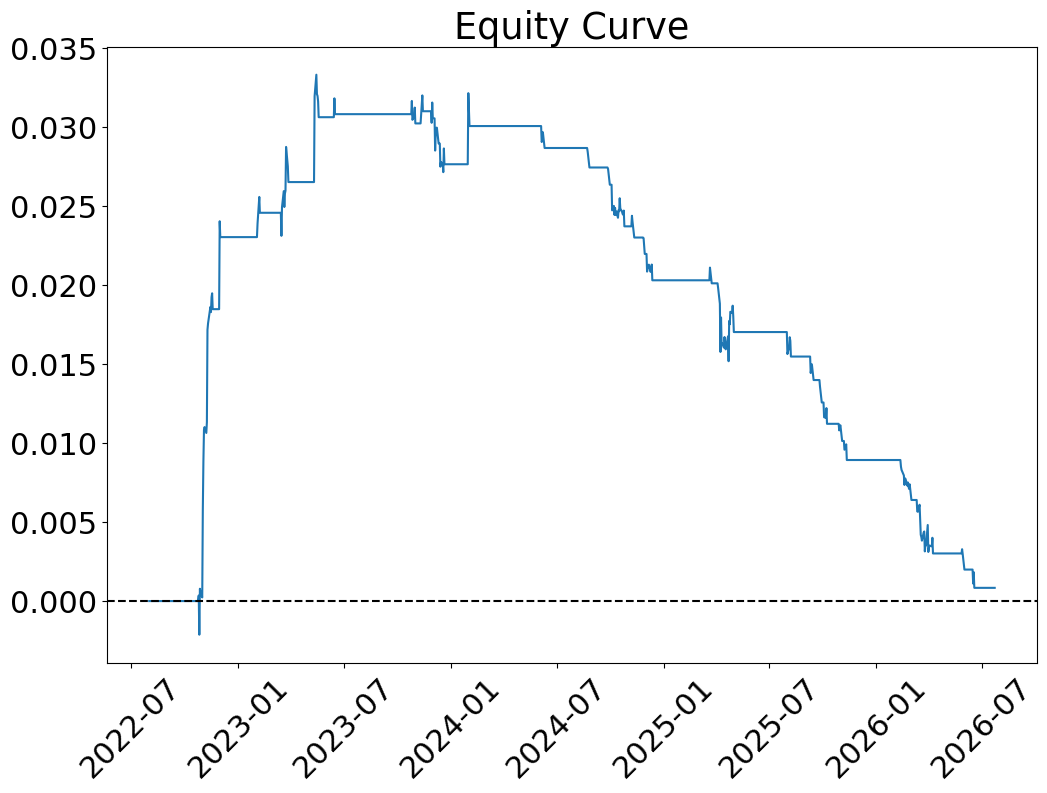

Combined IUSB & JCPB Volatility =  0.0006
Sharpe Ratio =  0.02
Max Drawdown =  0.03
Summary from 01-01-2022 to 31-12-2023 | Total PnL =  0.03 | Total Trades = 26 | Losing Trades = 14 | Win Rate =  46.15%
Summary from 01-01-2024 to 28-07-2026 | Total PnL = -0.03 | Total Trades = 44 | Losing Trades = 41 | Win Rate =  6.82%


Price,IUSB,JCPB,beta_series,spread,z_score,position,daily_pnl,net_pnl,trade_id
Date,,,,,,,,,
2022-07-29,41.181244,40.915222,NaN,NaN,NaN,0.0,NaN,NaN,0
2022-08-01,41.324974,41.029316,1.007205,0.000028,NaN,0.0,NaN,-0.0,0
2022-08-02,40.937645,40.787811,1.005435,-0.071852,NaN,0.0,-0.0,0.0,0
2022-08-03,41.127010,40.821121,1.006138,0.055325,NaN,0.0,0.0,0.0,0
2022-08-04,41.230305,40.921043,1.006514,0.042710,NaN,0.0,0.0,-0.0,0
...,...,...,...,...,...,...,...,...,...
2026-07-20,45.680000,46.459999,0.983425,-0.009932,-0.431077,0.0,0.0,0.0,70
2026-07-21,45.610001,46.380001,0.983421,-0.001089,0.126752,0.0,0.0,-0.0,70
2026-07-22,45.520000,46.299999,0.983385,-0.010729,-0.518130,0.0,-0.0,0.0,70


In [ ]:
# Asset 1 is the "dependent" leg (regressed on asset 2); asset 2 is the hedge leg.
TICKER1 = 'IUSB'
#iShares Core Universal USD Bond ETF

TICKER2 = 'JCPB'
#JPMorgan Core Plus Bond ETF

# Daily data. (Hourly data is capped at 730 days by Yahoo Finance, hence the PERIOD switch.)
INTERVAL = '1d'

if INTERVAL == '1h':
    PERIOD = '730d'
else:
    PERIOD = 'max'
    
# LOOKBACK : number of most recent trading days to use
# NOTIONAL : capital (in $) allocated to the first leg of each trade
# TRADE_COST : proportional cost of trading (0.0005 = 5 bps) on the traded value of both legs
LOOKBACK = 1000
NOTIONAL = 10000
TRADE_COST = 0.0005


# STEP 1: DATA ACQUISITION
# Download the full price history for a ticker and keep the last `lookback` rows.
def get_data1(ticker = TICKER1, lookback = LOOKBACK, interval = INTERVAL):
    df = yf.download(ticker, interval = interval, period=PERIOD)
    df.columns = df.columns.get_level_values(0)  

    if INTERVAL == '1d':
        df = df
    else:
        df = df.reset_index(drop = True)

    return df.iloc[-lookback:,:] 

def get_data2(ticker = TICKER2, lookback = LOOKBACK, interval = INTERVAL):
    
    df = yf.download(ticker, interval = interval, period=PERIOD)
    df.columns = df.columns.get_level_values(0)

    if INTERVAL == '1d':
        df = df
    else:
        df = df.reset_index(drop = True)

    return df.iloc[-lookback:,:] 
    
# Download both ETFs, keep only the closing prices, and align them on common dates.
def load_data():
    #Loading data sets and combining the close prices into one df
    df1 = get_data1()
    df2 = get_data2()

    price_1 = df1[['Close']].rename(columns ={'Close' : TICKER1})
    price_2 = df2[['Close']].rename(columns ={'Close' : TICKER2})

    df = pd.concat([price_1, price_2], axis = 1).dropna()
    
    # Plot the two price series to check visually that the pair moves together
    plt.plot(df)
    plt.xticks(rotation = 45)
    plt.legend([f'{TICKER1} Time Series', f'{TICKER2} Time Series'])
    plt.show()

    return df


# STEPS 2 & 3: DYNAMIC HEDGE RATIO (KALMAN FILTER) AND SIGNAL
# 1. Estimate a time-varying hedge ratio (beta) with a Kalman filter.
# 2. Form the spread  IUSB - beta * JCPB.
# 3. Standardise the spread into a 60-day rolling z-score, which is the trading signal.
def add_spread(df):
    price_1 = df[TICKER1]
    price_2 = df[TICKER2]
    # Lists that will collect the filtered beta (and the spread) for each day
    betas = []
    spread = []

    # Run a static OLS regression of IUSB on JCPB. Its slope is the starting guess for beta,
    # and its residual variance is used as the observation noise R.
    x = sm.add_constant(price_2)
    model = sm.OLS(price_1, x).fit()
    beta_0 = model.params[1]  # slope of the OLS fit = initial hedge ratio

    P_0 = 1  # initial uncertainty about beta (large, so the filter learns from the data quickly)
    R = model.resid.var()  # observation noise: variance of the OLS residuals
    Q = R * 0.00001  # process noise: small, so beta changes slowly (this controls how adaptive the filter is)
    # Current state estimate (beta) and its variance (P)
    beta = beta_0 
    P = P_0

    # Kalman filter loop: one predict + update cycle per trading day 
    for i in range(1, len(df)):
        H = price_2.iloc[i]     # observation coefficient: today's JCPB price
        # PREDICT: beta is expected to be unchanged (random walk), but uncertainty grows by Q
        P = P + Q
        z = price_1.iloc[i]  # observation: today's actual IUSB price
        # UPDATE: Kalman gain = share of the prediction error attributed to a change in beta.
        # (Scalar version of K = P H / (H P H + R); the "* 1" is a leftover from the matrix form.)
        K = (P * H) * 1 / (H * P * H + R)    
        x_pred = beta  # predicted beta (unchanged from yesterday)
        innovation = z - H * x_pred  # prediction error: actual minus predicted IUSB price
        beta  = innovation * K + x_pred  # corrected beta = prediction + gain * innovation
        P = (1 - K * H) * P  # uncertainty shrinks after incorporating the new observation
        betas.append(beta)  # store today's beta
        spread.append(price_1.iloc[i] - beta * price_2.iloc[i])  # spread using the filtered beta (recomputed as a Series below)


    # Attach the beta series to the data frame. The loop starts at day 1, so there is no beta for day 0 and the spread, z-score and strategy all begin one day later.
    df['beta_series']= pd.Series(betas, index = df.index[1:])
    beta_series = df['beta_series']
    # Spread = IUSB - beta_t * JCPB. Being long the spread means long IUSB and short beta units of JCPB.
    spread = price_1.iloc[1:] - beta_series * price_2.iloc[1:]
                                                        
    # Plot how the hedge ratio evolves over time (x-axis is the trading day index)
    plt.plot(betas)
    plt.title('Beta Progression Using Kalman Filter')
    plt.show()

    df['spread'] = spread

    # Rolling z-score: how many standard deviations the spread is from its own 60-day mean.
    # Using a rolling window means "unusual" is judged against recent behaviour. The first ~ 60 days are NaN while the window fills, so no trades can occur then.
    window = 60

    rolling_mean = spread.rolling(window).mean()
    rolling_std = spread.rolling(window).std()

    df['z_score'] = (spread - rolling_mean)/rolling_std

    # Plot the spread with its full-sample mean for reference
    plt.plot(spread, label='Spread')
    plt.axhline(spread.mean(), color = 'black', linestyle = '--', label = 'Mean')
    plt.title("Spread")
    plt.xticks(rotation = 45)
    plt.legend()
    plt.show()

    # Plot the z-score with the trading thresholds: entry at +/-2 and exit at +/-0.5
    plt.plot(df['z_score'], label = "Z Score")
    plt.axhline(2, color = 'red', linestyle = '--', label = 'Entry (+2)')
    plt.axhline(-2, color = 'green', linestyle = '--', label = 'Entry (-2)')
    plt.axhline(0.5, color = 'orange', linestyle = '--', label = 'Exit (0.5)')
    plt.axhline(-0.5, color = 'orange', linestyle = '--')
    plt.title("Rolling Z-Score")
    plt.xticks(rotation = 45)
    plt.legend()
    plt.tight_layout
    plt.show()

    return df


# STEP 4: TRADING RULES
# Convert the z-score into a position:
#   +1 = long the spread  (z < -2: spread unusually low, expect it to rise)
#   -1 = short the spread (z > +2: spread unusually high, expect it to fall)
#    0 = flat             (|z| < 0.5: spread has reverted to normal, close the trade)
# If none of these conditions hold, yesterday's position is carried forward.
def add_strategy(df):
    
    # Start flat; one position value per day
    position = np.zeros(len(df['z_score']))
    z_score = df['z_score'].values

    for i in range(1, len(position)):
        # By default keep yesterday's position (this is what makes the 0.5 exit band work)
        position[i] = position[i-1]

        if z_score[i] > 2:
            position[i] = -1
    
        elif z_score[i] < -2:
            position[i] = 1
    
        elif abs(z_score[i]) < 0.5:
            position[i] = 0

    df['position'] = position
    
    return df


# STEP 5: BACKTEST AND PERFORMANCE
# Compute the daily profit and loss of the strategy after transaction costs, then summarise it with the Sharpe Ratio, Max Drawdown and Win Rate, overall and for two sub-periods.
# PnL is expressed as a fraction of NOTIONAL, so 0.03 means a 3% return on the capital.
def test_strategy(df, notional = NOTIONAL, trade_cost = TRADE_COST):

    position = df['position'].values
    beta_series = df['beta_series'].iloc[1:]
    
    price_1 = df[TICKER1]
    price_2 = df[TICKER2]
    
    # Absolute daily change in position. Entering or exiting changes it by 1 and flipping from long to short by 2, which is how the extra cost of a reversal is captured.
    position_changes = np.abs(np.diff(position, prepend = position[0]))
    position_changes_trimmed = position_changes[1:]

    # Drop day 0, which has no beta, so every series lines up with the beta series
    price_1_trimmed = price_1.iloc[1:]
    price_2_trimmed = price_2.iloc[1:]
    position_trimmed = position[1:]

    # Position sizing: buy NOTIONAL dollars of IUSB, and hedge with beta times that amount of JCPB (so each day the hedge uses that day's filtered beta)
    shares_1 = notional / price_1_trimmed
    shares_2 = (notional * beta_series) / price_2_trimmed


    # Daily PnL: the position held at the close of day t earns the price changes from t to t+1 (long IUSB shares minus short JCPB shares, times +1 or -1). 
    # Using the next day's price change avoids look-ahead bias, because a signal can only be traded after it has been observed.
    daily_pnl = position_trimmed[:-1] * (shares_1.values[:-1] * price_1_trimmed.diff().values[1:] - shares_2.values[:-1] * price_2_trimmed.diff().values[1:])
    daily_pnl = daily_pnl / notional
    daily_pnl_series = pd.Series(daily_pnl, index = df[2:].index)
    df['daily_pnl'] = daily_pnl_series
    # Transaction costs: charged only on days the position changes, as a proportion of the total value traded across both legs
    transaction_costs = (position_changes_trimmed[:-1] * trade_cost * (shares_1.values[:-1] * price_1_trimmed[:-1] + shares_2[:-1] * price_2_trimmed[:-1])) / notional

    # Net PnL = gross PnL minus transaction costs; all metrics below use this
    net_pnl = daily_pnl - transaction_costs
    df['net_pnl'] = net_pnl 
    # Equity curve: cumulative net PnL over time
    cum_net_pnl = np.cumsum(net_pnl)
    plt.plot(cum_net_pnl)
    plt.axhline(0 , linestyle ='--', color = 'black')
    plt.xticks(rotation = 45)
    plt.title('Equity Curve')
    plt.show()

    # Sharpe Ratio = mean daily return / standard deviation of daily return, annualised by sqrt(252) trading days. No risk-free rate is subtracted, so this is the Sharpe Ratio of the raw returns.
    daily_std = net_pnl.std()
    daily_mean = net_pnl.mean()
    print('=' * 120)
    print(f'Combined {TICKER1} & {TICKER2} Volatility = {daily_std: .4f}')

    sharpe_ratio = (daily_mean / daily_std) * np.sqrt(252)
    print(f'Sharpe Ratio = {sharpe_ratio: .2f}')

    # Max Drawdown: largest fall from a previous peak of the equity curve
    max_pnl = np.maximum.accumulate(cum_net_pnl)

    max_drawdown = max(max_pnl - cum_net_pnl)
    print(f'Max Drawdown = {max_drawdown: .2f}')

    # Per-trade PnL list. (Built here but not used in the results below; the trade_id approach further down is what produces the trade statistics.)
    trade_pnl = []
    trade_start = 1

    for i in range(1, len(df['position'])):
        if position[i] != position[i-1]:
            if position[i-1] != 0:
                trade_pnl.append(np.sum(daily_pnl[trade_start:i]))
            trade_start = i


    trade_pnl = np.array(trade_pnl)

    # Give every trade a unique id: the counter increases each time the position changes. Grouping daily PnL by id then gives the PnL of each individual trade.
    trade_id = np.zeros(len(position), dtype = int)
    current_id = 0
    for i in range(1, len(position)):
        if position[i] != position[i-1]:
            current_id += 1
        trade_id[i] = current_id

    df['trade_id'] = trade_id

    # Summarise a date range: total PnL, number of trades, number of losing trades and win rate.
    # Trades with exactly zero PnL (for example, days when no position was held) are excluded.
    def summarize_period(df, start, end, pnl_col = 'net_pnl'):
        period = df.loc[start:end]
        total_pnl = period[pnl_col].sum()
        trade_pnls = period.groupby('trade_id')[pnl_col].sum()
        trade_pnls = trade_pnls[ trade_pnls != 0 ]
        n_trades = len(trade_pnls)
        losing_trades = (trade_pnls < 0).sum()
        win_rate = (trade_pnls > 0).sum() / n_trades
        return total_pnl, n_trades, losing_trades, win_rate

    # Compare two sub-periods. The first is the higher-volatility period; the second is the lower-volatility period in which the static-hedge strategy in PAIRS deteriorated.
    period_1_sum = summarize_period(df, '2022-01-01','2023-12-31')
    period_2_sum = summarize_period(df, '2024-01-01','2026-07-28')

    print('=' * 120)
    print(f'Summary from 01-01-2022 to 31-12-2023 | Total PnL = {period_1_sum[0] : .2f} | Total Trades = {period_1_sum[1]} | Losing Trades = {period_1_sum[2]} | Win Rate = {period_1_sum[3] : .2%}')

    print(f'Summary from 01-01-2024 to 28-07-2026 | Total PnL = {period_2_sum[0] : .2f} | Total Trades = {period_2_sum[1]} | Losing Trades = {period_2_sum[2]} | Win Rate = {period_2_sum[3] : .2%}')
    print('=' * 120)

    return df


# RUN THE FULL PIPELINE: load data -> hedge ratio & signal -> trading rules -> backtest
def main():
    df = load_data()
    df = add_spread(df)
    df = add_strategy(df)
    df = test_strategy(df)
    return df

df = main()
df

## Interpretation

Overall the strategy yields a **Sharpe Ratio** of **-0.60** and a **Max Drawdown** of **0.05**.
All profit and loss figures are expressed as a fraction of the \$10,000 notional, so a Max
Drawdown of 0.05 is a 5% peak-to-trough fall. A negative Sharpe Ratio means the strategy lost
money on a risk-adjusted basis once transaction costs are included.

**Hedge ratio.** The filtered beta drifts steadily downward from roughly 1.007 to 0.983 over the
sample. This matches the price chart, where IUSB and JCPB move almost one-for-one until early to
mid 2024 and JCPB then pulls ahead. The filter is absorbing that slow divergence into beta, which
is exactly what a static hedge ratio cannot do.

**Spread.** The spread is much more volatile in late 2022 - mid 2023, with swings of up to about
$0.2 - 0.3, than from 2024 onwards, when it mostly stays within about $0.05. This is
consistent with the lower-volatility regime I identified in `PAIRS`.

**Performance by period and comparison with the static hedge.** Both strategies use the same
signal rules and the same cost model, so the only difference is the hedge ratio.

| Metric | Kalman (dynamic beta) | Static OLS (`PAIRS`) |
|---|---|---|
| Sharpe Ratio | -0.60 | 0.07 |
| Max Drawdown | 0.05 | 0.02 |
| Win Rate, 2022 - 2023 | 40.74% | 50.00% |
| Win Rate, 2024 - Present | 8.06% | 31.11% |

The dynamic hedge ratio **did not fix the problem and was worse on every metric**. Both versions
lose their edge in the later period, but the Kalman version loses it more completely: fewer than
one trade in ten is profitable from 2024 onwards.

**Why might this be?** Two things combine. First, the z-score is scale-free: once the spread
becomes quieter, the same +/- 2 entry threshold is crossed by much smaller absolute moves.
Second, each position change costs 5 bps on both legs, roughly 10 bps of notional, and a reversal
from long to short counts as two changes. From the spread plot, typical moves in the later period
are a few cents on an ETF priced around \$45, which is the same order of magnitude as the cost of
a single trade. Trades can therefore lose money even when the spread does mean-revert. I have not
tested this explanation directly, but it fits the shrinking spread volatility, the very low win
rate in the later period. It also suggests the weakness lies in the signal and entry rules rather than in the hedge ratio
estimate.

## Limitations and Next Steps

- **Tuning.** `Q / R` and `P_0` were chosen by hand. A sensitivity analysis over `Q / R` would
  show whether any setting helps in the later period.
- **Model specification.** Adding an intercept to the state (estimating alpha and beta together)
  would make the model comparable to the OLS version in `PAIRS`.
- **Look-ahead in the starting value.** The initial beta comes from an OLS fit on the full sample.
  The effect fades quickly because `P_0` is large, but a strictly out-of-sample test would fit it
  only on an initial window.
- **Costs and signal.** Testing different cost levels, and using volatility-adjusted or cost-aware
  entry thresholds (or standing aside when spread volatility is low), would address the likely
  cause of the later losses.
- **Evidence.** Both backtests use a single 1000-day sample and a small number of trades, so
  the Sharpe Ratios should be read as indicative rather than statistically reliable.
  Walk-forward testing and other ETF pairs would give a more reliable picture.